# QRShield: Training the Phishing URL Detector

**Author:** Aakash Tiwari, M.S. Cybersecurity, Rowan University

QRShield checks the link inside a QR code **before** the user opens it. This notebook trains the detector that powers the scanner and the phone app.

Steps:
1. Load the PhiUSIIL phishing URL dataset
2. Look for dataset bias that a model could exploit
3. Show how a naive model learns a shortcut and fails on realistic links
4. Train a robust model on features of the web address host only
5. Evaluate it honestly with a split by domain
6. Choose a decision threshold and explain individual predictions
7. Save the model for the apps

In [1]:
import sys
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from urllib.parse import urlsplit
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
from xgboost import XGBClassifier

sys.path.insert(0, os.path.abspath('..'))
from qrshield.features import host_features, naive_features, FEATURE_NAMES, NAIVE_FEATURE_NAMES, _extract

os.makedirs('../figures', exist_ok=True)
os.makedirs('../models', exist_ok=True)

## 1. Load the data

PhiUSIIL Phishing URL Dataset (Prasad & Chandra, 2024, UCI Machine Learning Repository): 235,795 URLs. In the original file, **1 = legitimate and 0 = phishing**. We flip it so that **1 = phishing**.

Only the `URL` column is used. Many of the other 53 columns come from the web page's source code, which is not available when scanning a QR code before opening the link.

In [2]:
urls = pd.read_csv('../data/PhiUSIIL_Phishing_URL_Dataset.csv', encoding='utf-8-sig', usecols=['URL', 'label'])
urls['phishing'] = 1 - urls['label']
urls = urls.drop(columns='label').drop_duplicates('URL').reset_index(drop=True)
print(urls.shape)
urls['phishing'].value_counts()

(235370, 2)


phishing
0    134850
1    100520
Name: count, dtype: int64

In [3]:
pd.set_option('display.max_colwidth', 90)
pd.concat([urls[urls['phishing'] == 0].sample(5, random_state=1),
           urls[urls['phishing'] == 1].sample(5, random_state=1)])

,URL,phishing
92942,https://www.levelup.com,0
194530,https://www.notjusttoyz.com,0
117255,https://www.discover-suriname.com,0
92397,https://www.ecolabelindex.com,0
160791,https://www.cinematheque.fr,0
11705,https://bancodeoccidente.servidorprivad.repl.co/,1
203877,http://2001453526565.20331064515.my.id/failure.php,1
107600,http://www.eblagh-adiiran-ir.ga,1
28369,http://www.arkauto.ru,1
106543,https://emerald-exch-0utlook.firebaseapp.com/,1


## 2. Looking for dataset bias

Before training, check whether the two classes differ in ways that have nothing to do with phishing.

In [4]:
split = urls['URL'].map(lambda u: urlsplit(u if '://' in u else 'http://' + u))
urls['uses_https'] = urls['URL'].str.lower().str.startswith('https://')
urls['has_www'] = urls['URL'].str.lower().str.contains('://www.')
urls['has_path_or_query'] = split.map(lambda s: len(s.path.strip('/')) > 0 or bool(s.query))

bias = urls.groupby('phishing')[['uses_https', 'has_www', 'has_path_or_query']].mean().round(3)
bias.index = ['Legitimate', 'Phishing']
bias

,uses_https,has_www,has_path_or_query
Legitimate,1.000,1.000,0.000
Phishing,0.486,0.418,0.282


**Every legitimate URL is a homepage** in the form `https://www.domain.tld`: always https, always www, never a path. Phishing URLs vary.

Real QR codes for legitimate sites often point to pages like `https://restaurant.com/menu` or `https://rowan.edu/admissions`. A model that learns "path means phishing" would raise false alarms on exactly these.

## 3. The naive model and its shortcut

Train a model on features of the **full URL**, including length, path, https and www, with a random train/test split.

In [5]:
naive_X = pd.DataFrame([naive_features(u) for u in urls['URL']], columns=NAIVE_FEATURE_NAMES)
host_X = pd.DataFrame([host_features(u) for u in urls['URL']], columns=FEATURE_NAMES)
y = urls['phishing'].values
domains = urls['URL'].map(lambda u: _extract(u).top_domain_under_public_suffix or _extract(u).domain)
print(naive_X.shape, host_X.shape, domains.nunique())

(235370, 55) (235370, 48) 175509


In [6]:
train_idx, test_idx = train_test_split(np.arange(len(y)), test_size=0.2, random_state=0, stratify=y)

def xgb_model():
    return XGBClassifier(n_estimators=400, learning_rate=0.1, max_depth=6, subsample=0.9,
                         colsample_bytree=0.9, eval_metric='logloss', random_state=0, n_jobs=-1)

def report(name, model, X_test, y_test, threshold=0.5):
    p = model.predict_proba(X_test)[:, 1]
    pred = (p >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {'model': name, 'accuracy': round(accuracy_score(y_test, pred), 4),
            'precision': round(precision_score(y_test, pred), 4), 'recall': round(recall_score(y_test, pred), 4),
            'f1': round(f1_score(y_test, pred), 4), 'roc_auc': round(roc_auc_score(y_test, p), 4),
            'false_alarm_rate': round(fp / (fp + tn), 4)}

naive = xgb_model().fit(naive_X.iloc[train_idx], y[train_idx])
pd.DataFrame([report('Naive (full URL), random split', naive, naive_X.iloc[test_idx], y[test_idx])])

,model,accuracy,precision,recall,f1,roc_auc,false_alarm_rate
0,"Naive (full URL), random split",0.998,0.9998,0.9956,0.9977,0.9989,0.0001


Almost perfect. Now test it on **realistic legitimate links**: the same legitimate test URLs, but with ordinary paths added, the way they appear in real QR codes.

In [7]:
paths = ['/menu', '/about', '/contact', '/login', '/products/item?id=4821', '/events/2026/fall',
         '/admissions', '/en-us/support', '/blog/how-to-apply', '/order?table=12']
rng = np.random.default_rng(0)
legit_test = urls.iloc[test_idx][urls.iloc[test_idx]['phishing'] == 0]['URL'].values

def realistic(u):
    u = u if rng.random() < 0.5 else u.replace('://www.', '://')
    return u.rstrip('/') + rng.choice(paths)

realistic_urls = [realistic(u) for u in legit_test]
realistic_urls[:5]

['https://hoovershatchery.com/events/2026/fall',
 'https://www.damondnollan.com/contact',
 'https://www.cler.ch/about',
 'https://finerflora.com/blog/how-to-apply',
 'https://inspiredfilmandvideo.co.uk/order?table=12']

In [8]:
def false_alarm_on(urls_list, model, featurizer, names, threshold=0.5):
    X = pd.DataFrame([featurizer(u) for u in urls_list], columns=names)
    return round(float((model.predict_proba(X)[:, 1] >= threshold).mean()), 4)

print('Naive model, legitimate homepages flagged:', false_alarm_on(legit_test, naive, naive_features, NAIVE_FEATURE_NAMES))
print('Naive model, realistic legitimate links flagged:', false_alarm_on(realistic_urls, naive, naive_features, NAIVE_FEATURE_NAMES))

Naive model, legitimate homepages flagged: 0.0001


Naive model, realistic legitimate links flagged: 1.0


The naive model flags most ordinary legitimate links as phishing. Its high test score came from the shortcut, not from understanding phishing.

## 4. The robust model: host features only

QRShield uses only the **host** part of the address (for example `secure-paypa1-login.example.xyz`), after removing `www.`. Scheme and path are ignored, so the shortcut is not available.

Features include: length, subdomain count, dashes, digits, randomness (entropy), IP address hosts, look-alike characters (punycode and digit swaps like paypa1), brand names on domains the brand does not own, words like *login* and *verify*, and the domain ending.

In [9]:
robust_random = xgb_model().fit(host_X.iloc[train_idx], y[train_idx])
pd.DataFrame([report('Robust (host only), random split', robust_random, host_X.iloc[test_idx], y[test_idx])])

,model,accuracy,precision,recall,f1,roc_auc,false_alarm_rate
0,"Robust (host only), random split",0.845,0.9345,0.6851,0.7906,0.8901,0.0358


## 5. Honest evaluation: split by domain

With a random split, URLs from the same domain (for example many phishing pages on one hosting domain) can land in both train and test, which makes the score look better than it is. A **grouped split** keeps every domain entirely in train or entirely in test, so the model is tested on domains it has never seen.

In [10]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=0)
g_train, g_test = next(gss.split(host_X, y, groups=domains))

baseline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(host_X.iloc[g_train], y[g_train])
robust = xgb_model().fit(host_X.iloc[g_train], y[g_train])

results = pd.DataFrame([
    report('Naive (full URL), random split', naive, naive_X.iloc[test_idx], y[test_idx]),
    report('Robust (host only), random split', robust_random, host_X.iloc[test_idx], y[test_idx]),
    report('Logistic regression (host only), domain split', baseline, host_X.iloc[g_test], y[g_test]),
    report('Robust XGBoost (host only), domain split', robust, host_X.iloc[g_test], y[g_test]),
])
results

,model,accuracy,precision,recall,f1,roc_auc,false_alarm_rate
0,"Naive (full URL), random split",0.9980,0.9998,0.9956,0.9977,0.9989,0.0001
1,"Robust (host only), random split",0.8450,0.9345,0.6851,0.7906,0.8901,0.0358
2,"Logistic regression (host only), domain split",0.8370,0.9255,0.7140,0.8061,0.8972,0.0519
3,"Robust XGBoost (host only), domain split",0.8505,0.9472,0.7254,0.8216,0.9053,0.0365


In [11]:
g_legit = urls.iloc[g_test][urls.iloc[g_test]['phishing'] == 0]['URL'].values
g_realistic = [realistic(u) for u in g_legit]
robustness = pd.DataFrame([
    {'model': 'Naive (full URL)', 'homepages_flagged': false_alarm_on(legit_test, naive, naive_features, NAIVE_FEATURE_NAMES),
     'realistic_links_flagged': false_alarm_on(realistic_urls, naive, naive_features, NAIVE_FEATURE_NAMES)},
    {'model': 'Robust (host only)', 'homepages_flagged': false_alarm_on(g_legit, robust, host_features, FEATURE_NAMES),
     'realistic_links_flagged': false_alarm_on(g_realistic, robust, host_features, FEATURE_NAMES)},
])
robustness

,model,homepages_flagged,realistic_links_flagged
0,Naive (full URL),0.0001,1.0000
1,Robust (host only),0.0365,0.0365


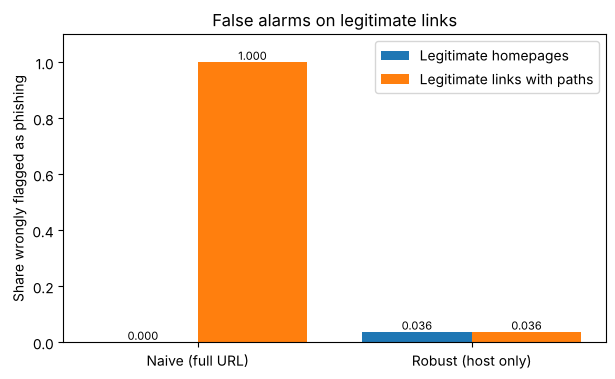

In [12]:
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(2)
bars1 = ax.bar(x - 0.2, robustness['homepages_flagged'], width=0.4, label='Legitimate homepages')
bars2 = ax.bar(x + 0.2, robustness['realistic_links_flagged'], width=0.4, label='Legitimate links with paths')
ax.bar_label(bars1, fmt='%.3f', fontsize=8)
ax.bar_label(bars2, fmt='%.3f', fontsize=8)
ax.set_xticks(x, robustness['model'])
ax.set_ylabel('Share wrongly flagged as phishing')
ax.set_title('False alarms on legitimate links')
ax.set_ylim(0, 1.1)
ax.legend()
plt.savefig('../figures/1_false_alarms_naive_vs_robust.png', dpi=200, bbox_inches='tight')
plt.show()

## 6. Phishing on shared platforms

Many phishing pages in this dataset are hosted on shared platforms: link shorteners, services like Google Docs and SharePoint, and free website builders like `*.web.app` or `*.github.io`. On these, **anyone can publish**.

The dataset has **no legitimate examples at all** on these platforms, so a model trained on them would learn "free website platform = phishing" and flag every personal portfolio on GitHub Pages. This is the same kind of shortcut as before.

QRShield removes these rows from training and handles them with clear rules instead:
- **Link shorteners and shared services:** **CAUTION** (the host cannot tell us anything about the page)
- **Free website platforms:** **PHISHING** if the user-chosen subdomain contains a brand name or words like *login* or *verify* (for example `metamask-wallet-restore.web.app`), otherwise **CAUTION**

In [13]:
from qrshield.features import platform_type

urls['platform'] = urls['URL'].map(platform_type).fillna('none')
pd.crosstab(urls['platform'], urls['phishing'].map({0: 'legitimate', 1: 'phishing'}))

phishing,legitimate,phishing
platform,,
hosting,0,28082
none,134847,70142
service,1,1579
shortener,2,717


In [14]:
keep = (urls['platform'] == 'none').values
hosts = urls['URL'].map(lambda u: u)
from qrshield.features import parse_host
host_text = urls['URL'].map(parse_host)

kept = np.where(keep)[0]
k_train, k_test = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=0).split(kept, y[kept], groups=domains.iloc[kept]))
k_train, k_test = kept[k_train], kept[k_test]
print('rows kept:', len(kept), 'train:', len(k_train), 'test:', len(k_test))

rows kept: 204989 train: 165535 test: 39454


## 7. Final model: blending two views of the host

Two models look at the host in different ways, and their predictions are averaged (blending, as in the House Prices project):
- **XGBoost on the hand-made features** (length, dashes, brands, keywords, domain ending ...). Its decisions can be explained.
- **Character n-gram model:** logistic regression on short letter sequences of the host (like `pay`, `ypa1`, `-ver`). It learns spelling patterns that the hand-made features miss.

In [15]:
from sklearn.feature_extraction.text import TfidfVectorizer

feature_model = xgb_model().fit(host_X.iloc[k_train], y[k_train])
ngram_model = make_pipeline(TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5), min_df=3, sublinear_tf=True),
                            LogisticRegression(max_iter=3000, C=2)).fit(host_text.iloc[k_train], y[k_train])

p_features = feature_model.predict_proba(host_X.iloc[k_test])[:, 1]
p_ngram = ngram_model.predict_proba(host_text.iloc[k_test])[:, 1]
p_blend = (p_features + p_ngram) / 2

def scores(name, p, threshold=0.5):
    pred = (p >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y[k_test], pred).ravel()
    return {'model': name, 'roc_auc': round(roc_auc_score(y[k_test], p), 4), 'recall': round(tp / (tp + fn), 4),
            'precision': round(tp / (tp + fp), 4), 'false_alarm_rate': round(fp / (fp + tn), 4)}

final_results = pd.DataFrame([scores('XGBoost, hand-made features', p_features),
                              scores('Character n-grams', p_ngram),
                              scores('Blend of both', p_blend)])
final_results

,model,roc_auc,recall,precision,false_alarm_rate
0,"XGBoost, hand-made features",0.8156,0.4782,0.8691,0.0337
1,Character n-grams,0.8785,0.6059,0.8839,0.0372
2,Blend of both,0.8765,0.5673,0.9261,0.0212


## 8. Choosing the threshold

For a QR scanner, missing a phishing link is worse than an occasional false alarm. Like the smoke alarm rule: **can't miss → lower the threshold → recall goes up**. But too many false alarms make people ignore the warning, so check both.

In [16]:
rows = []
for t in [0.3, 0.35, 0.4, 0.45, 0.5, 0.6]:
    pred = (p_blend >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y[k_test], pred).ravel()
    rows.append({'threshold': t, 'recall (phishing caught)': round(tp / (tp + fn), 4),
                 'precision': round(tp / (tp + fp), 4), 'false_alarm_rate': round(fp / (fp + tn), 4)})
thresholds = pd.DataFrame(rows)
thresholds

,threshold,recall (phishing caught),precision,false_alarm_rate
0,0.30,0.7194,0.7322,0.1231
1,0.35,0.6751,0.8000,0.0790
2,0.40,0.6348,0.8554,0.0502
3,0.45,0.5978,0.8955,0.0326
4,0.50,0.5673,0.9261,0.0212
5,0.60,0.5052,0.9679,0.0078


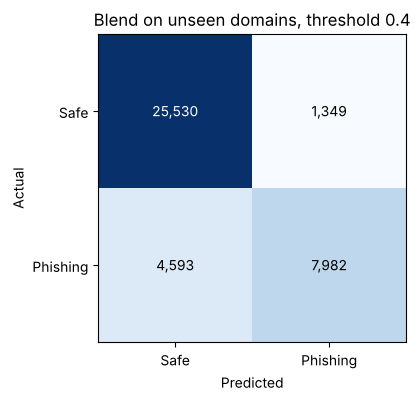

In [17]:
THRESHOLD = 0.4
cm = confusion_matrix(y[k_test], (p_blend >= THRESHOLD).astype(int))
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cm, cmap='Blues')
for i in range(2):
    for j in range(2):
        ax.text(j, i, f'{cm[i, j]:,}', ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black')
ax.set_xticks([0, 1], ['Safe', 'Phishing'])
ax.set_yticks([0, 1], ['Safe', 'Phishing'])
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')
ax.set_title(f'Blend on unseen domains, threshold {THRESHOLD}')
plt.savefig('../figures/2_confusion_matrix.png', dpi=200, bbox_inches='tight')
plt.show()

## 9. Which clues matter?

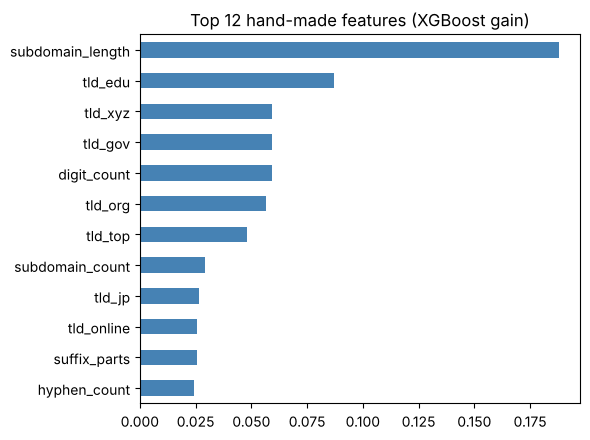

In [18]:
importance = pd.Series(feature_model.feature_importances_, index=FEATURE_NAMES).sort_values().tail(12)
importance.plot.barh(figsize=(6, 4.5), color='steelblue')
plt.title('Top 12 hand-made features (XGBoost gain)')
plt.tight_layout()
plt.savefig('../figures/3_feature_importance.png', dpi=200, bbox_inches='tight')
plt.show()

## 10. Save the models

Both models are retrained on **all kept rows**. The threshold is stored inside the XGBoost file. The scanner and the phone app load them from the `models` folder.

In [19]:
import joblib

final_features = xgb_model().fit(host_X.iloc[kept], y[kept])
booster = final_features.get_booster()
booster.feature_names = FEATURE_NAMES
booster.set_attr(threshold=str(THRESHOLD))
booster.save_model('../models/qrshield_xgb.json')

final_ngram = make_pipeline(TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5), min_df=3, sublinear_tf=True),
                            LogisticRegression(max_iter=3000, C=2)).fit(host_text.iloc[kept], y[kept])
joblib.dump(final_ngram, '../models/qrshield_ngram.joblib')
print('saved')

saved


## 11. The full system on example links

The complete QRShield check: trusted list, platform rules, then the blended model. These links are made up for the demo. Do not visit them.

In [20]:
from qrshield.service import QRShield

shield = QRShield(db_path=':memory:', model_dir='../models')
examples = ['https://www.rowan.edu/admissions', 'https://www.google.com/maps', 'https://restaurant-menu.com/menu?table=4',
            'https://docs.google.com/forms/d/e/abc/viewform', 'https://bit.ly/3xYz12',
            'http://secure-paypa1-verify-account.xyz/login', 'https://metamask-wallet-restore.web.app',
            'https://cool-portfolio.github.io', 'http://192.168.14.7/bank/login', 'https://amazon.account-update-billing.top/signin']
pd.DataFrame([{'host': r['host'], 'verdict': r['verdict'],
               'risk': None if r['risk'] is None else round(r['risk'], 3), 'reasons': '; '.join(r['reasons'])}
              for r in map(shield.check, examples)])

,host,verdict,risk,reasons
0,rowan.edu,SAFE,0.000,on your trusted list
1,google.com,SAFE,0.000,on your trusted list
2,restaurant-menu.com,SAFE,0.251,
3,docs.google.com,CAUTION,NaN,shared service where anyone can publish content
4,bit.ly,CAUTION,NaN,link shortener hides the real destination
5,secure-paypa1-verify-account.xyz,PHISHING,1.000,"contains words like login, verify or account; domain ending .xyz; imitates a brand nam..."
6,metamask-wallet-restore.web.app,PHISHING,NaN,"brand name on a free website platform; contains words like login, verify or account"
7,cool-portfolio.github.io,CAUTION,NaN,free website platform where anyone can publish
8,192.168.14.7,PHISHING,0.993,many numbers in the address; domain name looks random; unusual domain name length
9,amazon.account-update-billing.top,PHISHING,0.999,"domain ending .top; contains words like login, verify or account; long subdomain part"


## Conclusions

1. **The dataset contains a strong shortcut.** All legitimate URLs are homepages with https and www. A model trained on the full URL scored almost perfectly on its test split, but flagged every legitimate link with a path as phishing.
2. **Using only the host removes the shortcut.** The host-only model gives the same answer for a homepage and for a link with a path on the same site.
3. **A split by domain gives an honest estimate** on domains the model has never seen. Scores are lower than with a random split, and closer to what a real user would experience.
4. **Shared platforms need rules, not predictions.** The dataset has no legitimate links on shared platforms, so a model would learn to flag all of them. QRShield answers CAUTION for these, and PHISHING only when the chosen subdomain contains a brand or words like *login*.
5. **The honest numbers are much lower than the naive ones.** On regular domains the model has never seen, the blend catches about 63% of phishing links with a 5% false alarm rate at threshold 0.4, compared with the 99.8% accuracy the naive model appeared to reach.
6. **Blending reduces false alarms.** The character n-gram model alone has a similar AUC, but at threshold 0.5 the blend raises half as many false alarms (2.1% vs 3.7%).

## Limitations
- Phishing pages on a **compromised legitimate domain** look safe, because the host itself is trustworthy. Catching these needs the page content or a reputation service.
- Legitimate URLs in this dataset are mostly popular homepages, so false alarm rates on small or new legitimate sites may be higher.
- Brand, keyword and platform lists are written by hand and need updating as attackers change tactics.
- Phishing on free website platforms without brand names or keywords in the subdomain only gets a CAUTION warning.